# 3. Results and hazard maps

This notebook reads the **saved predictions** of the two scored folds (2024 and 2023) and shows the results table, the calibration curve and sample hazard maps. It needs no raw data and no training. Both folds were development folds; see `docs/RESULTS.md`.

**Provisional values.** Every fold-2023 value, and every probability of detection, false alarm ratio and critical success index, is provisional and labelled so below. Three limits (Limitations in `docs/MODEL.md`): (1) fold-2023 numbers use soil-moisture anomaly inputs whose norm includes later 2023 weather; (2) every model's settings were chosen on scored rows; (3) the fold-2023 alert threshold was chosen on fold-2024 labels (`evaluation.thresholds()`, the other-fold rule). Nothing is removed; corrected numbers will replace these when they exist.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deep_multimodal import evaluation, hazard_map, metrics

PREDICTIONS = Path('..') / 'results' / 'saved_predictions'
folds = {year: evaluation.load_fold_predictions(PREDICTIONS, year) for year in evaluation.FOLDS}
{year: len(f.label) for year, f in folds.items()}

{2024: 725441, 2023: 936380}

## The same rows for both models

The frozen baseline (extended boosting) and the deep model are scored on the same rows with the same labels.

In [2]:
rows = []
for year, fold in folds.items():
    for model in ['baseline', 'deep']:
        rows.append(dict(fold=year, model=model, average_precision=metrics.average_precision(fold.label, fold.raw[model])))
pd.DataFrame(rows).pivot(index='fold', columns='model', values='average_precision').rename(index={2023: '2023 (provisional)'}).round(4)

model,baseline,deep
fold,,
2023 (provisional),0.1797,0.2532
2024,0.2267,0.2913


## The full table

The committed table (made by `scripts/regenerate_results.py`). Only average precision has an interval; every other value is a point estimate. Fold-2023 columns and the probability of detection, false alarm ratio and critical success index rows are labelled provisional.

In [3]:
table = pd.read_csv(Path('..') / 'results' / 'results_table.csv')
THRESHOLDED = ['Probability of detection', 'False alarm ratio (lower is better)', 'Critical success index']

def provisional(t):
    """Label fold-2023 columns and the thresholded rows provisional (docs/MODEL.md, Limitations); values are unchanged."""
    return t.rename(columns={2023: '2023 (provisional)'}, level=0).rename(index={k: k + ' (provisional)' for k in THRESHOLDED})

whole = table[table.rows_scored == 'All rows'].set_index(['fold', 'model']).T
provisional(whole).round(4)

fold                                                          2024  \
model                                              Frozen baseline   
rows_scored                                               All rows   
Average precision (pooled)                                0.226737   
Average precision, ranking cells within each day          0.193196   
Average precision, ranking days within each cell          0.392685   
AUROC (pooled)                                            0.834612   
AUROC, ranking cells within each day                        0.8081   
AUROC, ranking days within each cell                      0.795727   
Precision, top 1% of cells per day                        0.103308   
Recall, top 1% of cells per day                           0.056676   
Lift, top 1% of cells per day                             6.962245   
Precision, top 5% of cells per day                        0.068377   
Recall, top 5% of cells per day                           0.209169   
Lift, top 5% of cells per day                             4.958769   
Precision, top 10% of cells per day                       0.054605   
Brier score (lower is better)                             0.013599   
Brier score of the cell climatology (reference)            0.01397   
Brier skill score against the cell climatology            0.026556   
Log loss (lower is better)                                0.062767   
Calibration error, ECE (lower is better)                  0.000475   
Alert threshold (probability, fixed on the othe...        0.065611   
Share of cell-days alerted                                0.041817   
Probability of detection (provisional)                    0.286067   
False alarm ratio (lower is better) (provisional)         0.901947   
Critical success index (provisional)                      0.078776   
Rows                                                      725441.0   
Fire onsets                                                36841.0   
Fire rate (population-weighted)                           0.014333   
Average precision, 95% interval low                       0.170427   
Average precision, 95% interval high                      0.267931   

fold                                                                      \
model                                              Deep multimodal model   
rows_scored                                                     All rows   
Average precision (pooled)                                      0.291338   
Average precision, ranking cells within each day                0.243213   
Average precision, ranking days within each cell                0.424578   
AUROC (pooled)                                                  0.857546   
AUROC, ranking cells within each day                            0.833515   
AUROC, ranking days within each cell                            0.811686   
Precision, top 1% of cells per day                              0.157395   
Recall, top 1% of cells per day                                 0.073804   
Lift, top 1% of cells per day                                   9.782845   
Precision, top 5% of cells per day                              0.088778   
Recall, top 5% of cells per day                                 0.252816   
Lift, top 5% of cells per day                                   6.337863   
Precision, top 10% of cells per day                             0.065472   
Brier score (lower is better)                                   0.013331   
Brier score of the cell climatology (reference)                  0.01397   
Brier skill score against the cell climatology                  0.045752   
Log loss (lower is better)                                      0.060024   
Calibration error, ECE (lower is better)                        0.000215   
Alert threshold (probability, fixed on the othe...              0.077752   
Share of cell-days alerted                                      0.035016   
Probability of detection (provisional)                          0.317255   
False

## Where the deep model does not win

The quiet stratum holds rows with no neighbouring fire detection in the previous 7 days. The deep model is ahead when ranking cells within a day, but not when ranking days within a cell, and its thresholded detection on 2023 (provisional) is lower. Calibration error on 2023 (provisional) is higher too.

In [4]:
quiet = table[table.rows_scored == 'Quiet stratum'].set_index(['fold', 'model']).T
quiet.loc[['Average precision (pooled)', 'Average precision, ranking cells within each day', 'Average precision, ranking days within each cell', 'Probability of detection', 'Critical success index']].pipe(provisional).round(4)

fold                                                        2024  \
model                                            Frozen baseline   
Average precision (pooled)                              0.034298   
Average precision, ranking cells within each day        0.079039   
Average precision, ranking days within each cell        0.499381   
Probability of detection (provisional)                  0.019737   
Critical success index (provisional)                    0.012099   

fold                                                                    \
model                                            Deep multimodal model   
Average precision (pooled)                                    0.063991   
Average precision, ranking cells within each day              0.118883   
Average precision, ranking days within each cell              0.494144   
Probability of detection (provisional)                        0.019737   
Critical success index (provisional)                          0.018857   

fold                                             2023 (provisional)  \
model                                               Frozen baseline   
Average precision (pooled)                                 0.019685   
Average precision, ranking cells within each day           0.053348   
Average precision, ranking days within each cell           0.433053   
Probability of detection (provisional)                     0.024064   
Critical success index (provisional)                       0.011385   

fold                                                                    
model                                            Deep multimodal model  
Average precision (pooled)                                    0.034722  
Average precision, ranking cells within each day               0.07873  
Average precision, ranking days within each cell              0.405853  
Probability of detection (provisional)                        0.007353  
Critical success index (provisional)                           0.00721

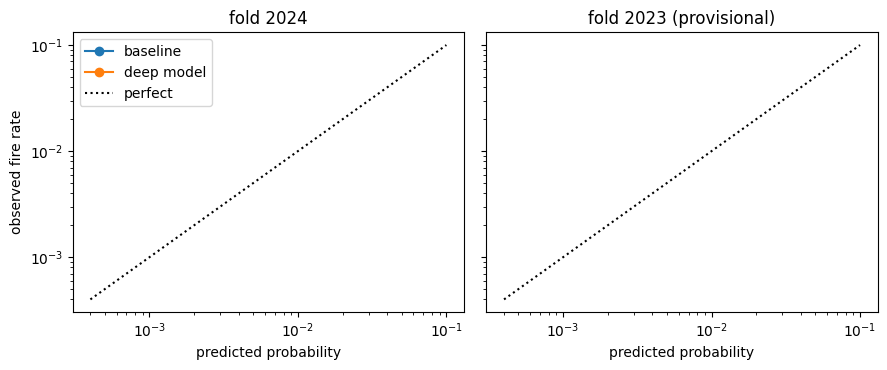

In [5]:
calibration = pd.read_csv(Path('..') / 'results' / 'calibration_curve.csv')
figure, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for axis, year in zip(axes, [2024, 2023]):
    for model, label in [('baseline', 'baseline'), ('deep', 'deep model')]:
        c = calibration[(calibration.fold == year) & (calibration.rows_scored == 'all rows') & (calibration.model == model)]
        axis.loglog(c.mean_prediction, c.observed_rate, 'o-', label=label)
    axis.plot([4e-4, 0.1], [4e-4, 0.1], 'k:', label='perfect')
    axis.set_title(f'fold {year}' + (' (provisional)' if year == 2023 else '')); axis.set_xlabel('predicted probability')
axes[0].set_ylabel('observed fire rate'); axes[0].legend()
plt.tight_layout(); plt.show()

## Hazard maps

A hazard map draws each cell's probability of a fire starting that day, at the cell centre. It is a probability per 5 km cell, not an ignition point. Rings mark the fires that started. The maps show the day with the most fire starts in each fold.

In [6]:
cells = pd.read_csv(PREDICTIONS / 'cells.csv')
fold = folds[2024]
day = hazard_map.busiest_day(fold)
frame = hazard_map.day_table(fold, cells, day)
hazard_map.draw_day(frame, f'Deep multimodal model, fold 2024, day {day}')
plt.show()

/var/folders/8t/p_kcbwsj6bd20k8tyrsx54rw0000gn/T/ipykernel_90344/3608571574.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


The baseline gives different probabilities on the same day. Comparing the two on the same map shows where they disagree.

In [7]:
hazard_map.draw_day(frame, f'Frozen baseline, fold 2024, day {day}', column='baseline')
plt.show()

/var/folders/8t/p_kcbwsj6bd20k8tyrsx54rw0000gn/T/ipykernel_90344/1899016100.py:2: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## A quieter day

On a day with few fire starts the model has little recent fire to follow, which is where its skill is weakest.

In [8]:
days, counts = np.unique(fold.day[fold.label == 1], return_counts=True)
quiet_day = int(days[np.argsort(counts)[len(counts) // 4]])
frame = hazard_map.day_table(fold, cells, quiet_day)
hazard_map.draw_day(frame, f'Deep multimodal model, fold 2024, day {quiet_day}')
plt.show()

/var/folders/8t/p_kcbwsj6bd20k8tyrsx54rw0000gn/T/ipykernel_90344/4208924609.py:5: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
